# Phase 1
My job is to get CLIP's predictions. My teammate analyses the mistakes.

CLIP is already trained. I show it our 5,000 animal photos and the 50 class names, and write down which name it picks for each photo

In [3]:
%pip install -q open_clip_torch pandas matplotlib tqdm requests pillow

Note: you may need to restart the kernel to use updated packages.


In [17]:
import json, zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import open_clip
from PIL import Image
from tqdm.auto import tqdm
import requests
import matplotlib.pyplot as plt

In [7]:
BASE = Path(".").resolve()

MANIFEST = BASE / "awa2_subset_5000.csv"
IMG_DIR = BASE / "awa2_work" / "JPEGImages"

# 32kb. only want classes.txt out of it, not the 13gb photo zip
BASE_URL = "https://cvml.ista.ac.at/AwA2/AwA2-base.zip"

OUT = BASE / "results"
OUT.mkdir(exist_ok=True)

MODEL_NAME = "ViT-B-16-quickgelu"
PRETRAINED = "openai"
PROMPT = "a photo of a {}."
BATCH = 32   

print("manifest", "ok" if MANIFEST.exists() else "MISSING", MANIFEST)
print("images  ", "ok" if IMG_DIR.exists() else "MISSING", IMG_DIR)

manifest ok /Users/hassinrahman/JKU AI/Last Sem/AI_in_Vis/awa2_subset_5000.csv
images   ok /Users/hassinrahman/JKU AI/Last Sem/AI_in_Vis/awa2_work/JPEGImages


## class names

The dataset writes spaces as plus signs, so the folder is `grizzly+bear` but the sentence I give the model should say "grizzly bear". I only do that swap inside the sentence. The saved label stays `grizzly+bear`, because that is the name in the csv.

I don't type the names myself and I don't sort them alphabetically. I read them from `classes.txt` in the official order.
If the order got scrambled, "score number 3" would no longer mean animal number 3, and every right/wrong flag would be wrong.

In [8]:
base_zip = BASE / "AwA2-base.zip"
if not base_zip.exists():
    r = requests.get(BASE_URL, timeout=60)
    r.raise_for_status()
    base_zip.write_bytes(r.content)

with zipfile.ZipFile(base_zip) as z:
    fname = [n for n in z.namelist() if n.endswith("classes.txt")][0]
    text = z.read(fname).decode("utf-8")

# lines look like "7 horse"
pairs = []
for line in text.strip().splitlines():
    i, name = line.split()
    pairs.append((int(i), name))
pairs.sort()   # id 1 .. 50, official order

class_names = [name for _, name in pairs]
name_to_idx = {n: i for i, n in enumerate(class_names)}

assert len(class_names) == 50 and len(set(class_names)) == 50
print(class_names[:5], "...", class_names[-1])

def readable(name):
    return name.replace("+", " ")

['antelope', 'grizzly+bear', 'killer+whale', 'beaver', 'dalmatian'] ... dolphin


In [9]:
manifest = pd.read_csv(MANIFEST)[["image_path", "true_label"]].copy()
print(len(manifest), "photos,", manifest["true_label"].nunique(), "animals")

# a typo in the csv would silently make the wrong column
bad = set(manifest["true_label"]) - set(class_names)
assert not bad, bad

missing = [p for p in manifest["image_path"] if not (IMG_DIR / p).exists()]
print("missing files:", len(missing))
assert not missing, missing[:8]

5000 photos, 50 animals
missing files: 0


## load the model

The model is OpenAI's CLIP ViT-B/16, frozen. Nothing here is training.

It turns a photo into 512 numbers and a sentence into 512 numbers, so I can compare them directly.
The 50 sentences don't change between photos, so I encode them once, not 5,000 times.

I use the model's own preprocessing (resize, center crop, colour normalization). With my own resizing I wouldn't be testing the model we agreed on anymore.

One fix: my first version loaded `ViT-B-16` and open_clip warned about a QuickGELU mismatch. The OpenAI weights were trained with a slightly different activation function than that config uses.
So I load `ViT-B-16-quickgelu`. Same OpenAI weights, matching architecture.

In [10]:
model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model = model.to(device).eval()

prompts = [PROMPT.format(readable(c)) for c in class_names]
print(prompts[0])
print(prompts[8])

with torch.no_grad():
    tokens = tokenizer(prompts).to(device)
    text_feat = model.encode_text(tokens)
    text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)

text_feat.shape   # (50, 512)

a photo of a antelope.
a photo of a blue whale.


torch.Size([50, 512])

## the actual loop

open photo, make it rgb (a few files are grayscale and clip refuses them), preprocess, encode.

then one dot product against the 50 text vectors. because both sides are normalised, that dot product *is* the cosine similarity.

these numbers are not probabilities. 0.31 is not "31% sure". it is just "closer to this name than to the others".

i walk the manifest in order and write scores into the same row. no shuffle, no DataLoader. row 400 of `sims` is photo 400.

In [12]:
n = len(manifest)
sims = np.empty((n, 50), dtype=np.float32)
widths, heights, modes = [], [], []
paths = manifest["image_path"].tolist()

with torch.no_grad():
    for start in tqdm(range(0, n, BATCH)):
        batch = paths[start:start + BATCH]
        tensors = []
        for rel in batch:
            img = Image.open(IMG_DIR / rel)
            modes.append(img.mode)
            img = img.convert("RGB")
            widths.append(img.size[0])
            heights.append(img.size[1])
            tensors.append(preprocess(img))

        x = torch.stack(tensors).to(device)
        img_feat = model.encode_image(x)
        img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
        sims[start:start + len(batch)] = (img_feat @ text_feat.T).float().cpu().numpy()

print(sims.shape)

  0%|          | 0/157 [00:00<?, ?it/s]

(5000, 50)


## predictions.csv

for each photo the winner is just `argmax` of that row.
`margin` is winner minus runner-up. a tiny margin means clip almost flipped a coin (ox vs cow, blue whale vs humpback).
`true_label_rank` is where the real animal landed. 1 means we got it. 4 means three other names beat it.

In [13]:
order = np.argsort(-sims, axis=1)
rows = np.arange(n)
top1 = order[:, 0]
top2 = order[:, 1]

true = manifest["true_label"].tolist()
pred = [class_names[i] for i in top1]
true_idx = np.array([name_to_idx[t] for t in true])

top1_sim = sims[rows, top1]
top2_sim = sims[rows, top2]
true_sim = sims[rows, true_idx]
true_rank = (order == true_idx[:, None]).argmax(axis=1) + 1
top5 = ["|".join(class_names[j] for j in order[i, :5]) for i in range(n)]

out = pd.DataFrame({
    "image_path": paths,
    "true_label": true,
    "predicted_label": pred,
    "correct": [a == b for a, b in zip(true, pred)],
    "top1_similarity": top1_sim,
    "top2_label": [class_names[i] for i in top2],
    "top2_similarity": top2_sim,
    "margin": top1_sim - top2_sim,
    "true_label_similarity": true_sim,
    "true_label_rank": true_rank,
    "top5_labels": top5,
    "width": widths,
    "height": heights,
    "orig_mode": modes,
})

assert len(out) == 5000
assert (out["correct"] == (out["true_label_rank"] == 1)).all()

out.to_csv(OUT / "predictions.csv", index=False)
print(f"accuracy {out['correct'].mean():.4f}   wrong {(~out['correct']).sum()} / {len(out)}")
print("wrote", OUT / "predictions.csv")

accuracy 0.9208   wrong 396 / 5000
wrote /Users/hassinrahman/JKU AI/Last Sem/AI_in_Vis/results/predictions.csv


In [14]:
# so in two weeks i can still say what this file was
config = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "model": MODEL_NAME,
    "pretrained": PRETRAINED,
    "prompt": PROMPT,
    "n_images": 5000,
    "device": device,
    "torch": torch.__version__,
    "open_clip": open_clip.__version__,
    "note": "zero-shot. scores are cosine similarity, not probabilities",
}
(OUT / "experiment_config.json").write_text(json.dumps(config, indent=2))
pd.DataFrame({"idx": range(50), "class_name": class_names}).to_csv(OUT / "class_order.csv", index=False)
np.save(OUT / "similarity_matrix.npy", sims)
print("also wrote class_order.csv, similarity_matrix.npy, experiment_config.json")

also wrote class_order.csv, similarity_matrix.npy, experiment_config.json


In [15]:
p = pd.read_csv(OUT / "predictions.csv")
print("accuracy", round(p["correct"].mean(), 4))
print()
print(p.groupby("true_label")["correct"].mean().sort_values().head(8).round(3))
print()
err = p[~p["correct"]]
print(err.groupby(["true_label", "predicted_label"]).size().sort_values(ascending=False).head(10))

accuracy 0.9208

true_label
blue+whale    0.28
ox            0.50
rat           0.73
weasel        0.76
mouse         0.83
otter         0.84
walrus        0.85
cow           0.86
Name: correct, dtype: float64

true_label     predicted_label
blue+whale     humpback+whale     67
ox             buffalo            26
               cow                24
rat            mouse              15
cow            ox                 10
otter          beaver             10
beaver         otter               8
hamster        mouse               8
spider+monkey  chimpanzee          8
chimpanzee     spider+monkey       8
dtype: int64


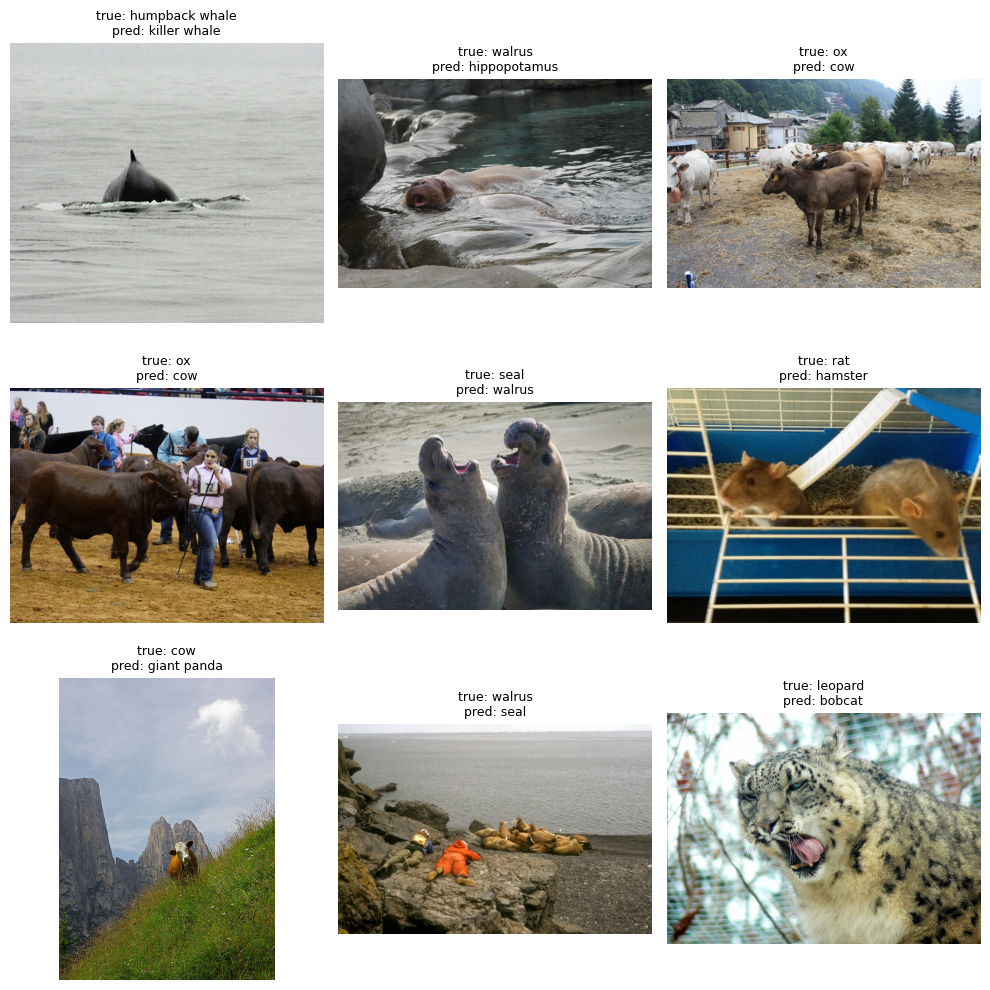

In [16]:
# nine misses, picked with a fixed seed so the picture doesn't change every time i reopen this
show = p[~p["correct"]].sample(9, random_state=1)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, (_, r) in zip(axes.flat, show.iterrows()):
    ax.imshow(Image.open(IMG_DIR / r["image_path"]).convert("RGB"))
    ax.set_title(f"true: {readable(r['true_label'])}\npred: {readable(r['predicted_label'])}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()